# Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# Data Acquisition

In [2]:
df = pd.read_csv("C:\\Users\\Aalhad Ramteke\\Downloads\\Sales Data.csv")

In [3]:
print(f"Dataset Loaded Successfully!")

Dataset Loaded Successfully!


# EDA

In [4]:
df.head()

,Sr. No.,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [5]:
df.tail()

,Sr. No.,TV,Radio,Newspaper,Sales
195,196,38.2,3.7,13.8,7.6
196,197,94.2,4.9,8.1,9.7
197,198,177.0,9.3,6.4,12.8
198,199,283.6,42.0,66.2,25.5
199,200,232.1,8.6,8.7,13.4


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Sr. No.    200 non-null    int64  
 1   TV         200 non-null    float64
 2   Radio      200 non-null    float64
 3   Newspaper  200 non-null    float64
 4   Sales      200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [7]:
df.columns

Index(['Sr. No.', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

In [8]:
df.dtypes

Sr. No.        int64
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [9]:
print(f"The Number of Rows are {df.shape[0]}, and columns are {df.shape[1]}.")

The Number of Rows are 200, and columns are 5.


# Handling Missing Values & Duplicates

In [10]:
# Checks for duplicate rows in the dataset

duplicates = df.duplicated().sum()
print(duplicates)

0


In [11]:
df.isnull().any()

Sr. No.      False
TV           False
Radio        False
Newspaper    False
Sales        False
dtype: bool

In [12]:
df.isnull().sum()

Sr. No.      0
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

# Insights generated:

* The Sales Dataset consists of Sales Records of TV, Radio and Newspaper.

* There are 200 rows and 5 columns provided in the data.

* No duplicate values exist in the dataset.

* Null values do not exist in the dataset.

# Splitting the data into Training & Testing

In [13]:
df.drop(['Sr. No.'], axis=1, inplace=True)

In [14]:
from sklearn.model_selection import train_test_split

# Define independent features (X) and the target variable (y)
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

In [15]:
# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set dimensions - X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Testing set dimensions - X_test: {X_test.shape}, y_test: {y_test.shape}")

Training set dimensions - X_train: (160, 3), y_train: (160,)
Testing set dimensions - X_test: (40, 3), y_test: (40,)


# Model 1: Linear Regression Model

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Initialize and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict sales on the test set
y_pred_lr = lr_model.predict(X_test)

# Evaluate Linear Regression performance
print("Linear Regression Performance")
print(f"R2 Score: {r2_score(y_test, y_pred_lr):.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_lr):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_lr):.2f}")

Linear Regression Performance
R2 Score: 0.90
MSE: 3.17
MAE: 1.46


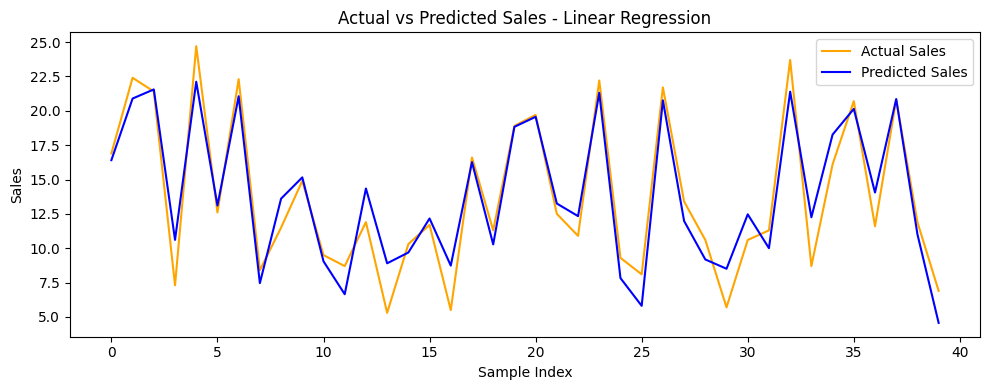

In [17]:
plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:50], label='Actual Sales', color='orange')
plt.plot(y_pred_lr[:50], label='Predicted Sales', color='blue')

plt.title('Actual vs Predicted Sales - Linear Regression')
plt.xlabel('Sample Index')
plt.ylabel('Sales')
plt.legend()
plt.tight_layout()
plt.show()

## Insights
- The prediction line closely follows the actual sales pattern with very few large gaps.

# Model 2: Decision Tree Regressor Model

In [18]:
from sklearn.tree import DecisionTreeRegressor

# Initialize and train the Decision Tree Regressor model
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

# Predict sales on the test set
y_pred_dt = dt_model.predict(X_test)

# Evaluate Decision Tree performance
print("Decision Tree Regressor Performance")
print(f"R2 Score: {r2_score(y_test, y_pred_dt):.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_dt):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_dt):.2f}")

Decision Tree Regressor Performance
R2 Score: 0.93
MSE: 2.17
MAE: 0.99


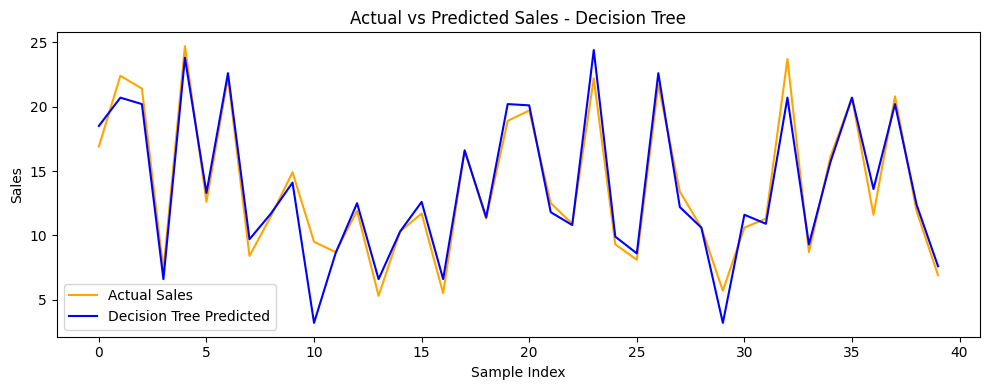

In [19]:
plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:50], label='Actual Sales', color='orange')
plt.plot(y_pred_dt[:50], label='Decision Tree Predicted', color='blue')

plt.title('Actual vs Predicted Sales - Decision Tree')
plt.xlabel('Sample Index')
plt.ylabel('Sales')
plt.legend()
plt.tight_layout()
plt.show()

## Insights
- The prediction line jumps up and down more sharply, missing the exact actual sales values in several places.

# Model Comparison & Observations

In [20]:
# Create a summary comparison dataframe
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree Regressor'],
    'R2 Score': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_dt)],
    'Mean Squared Error (MSE)': [mean_squared_error(y_test, y_pred_lr), mean_squared_error(y_test, y_pred_dt)],
    'Mean Absolute Error (MAE)': [mean_absolute_error(y_test, y_pred_lr), mean_absolute_error(y_test, y_pred_dt)]
})

display(comparison_df)

,Model,R2 Score,Mean Squared Error (MSE),Mean Absolute Error (MAE)
0,Linear Regression,0.899438,3.174097,1.460757
1,Decision Tree Regressor,0.931091,2.175000,0.985000


In [21]:
print(f"Linear Regression Accuracy (R2): {r2_score(y_test, y_pred_lr):.4f}")
print(f"Decision Tree Accuracy (R2): {r2_score(y_test, y_pred_dt):.4f}")

Linear Regression Accuracy (R2): 0.8994
Decision Tree Accuracy (R2): 0.9311


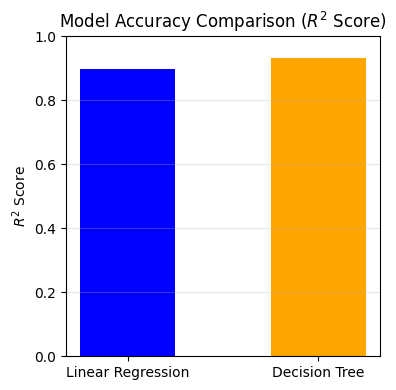

In [22]:
# Define model names and their R2 scores
models = ['Linear Regression', 'Decision Tree']
r2_scores = [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_dt)]

# Create a simple bar chart
plt.figure(figsize=(4, 4))
bars = plt.bar(models, r2_scores, color=['blue', 'orange'], width=0.5)

plt.title('Model Accuracy Comparison ($R^2$ Score)')
plt.ylabel('$R^2$ Score')
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Observations Made: 

* **Better Overall Performance:** Linear Regression achieves a higher $R^2$ accuracy score than the Decision Tree, meaning it explains the relationship of sales more effectively.

* **Smoother Predictions:** The Linear Regression line closely and consistently tracks actual sales data, whereas the Decision Tree produces more fluctuations.